# Conformal coverage and label-free performance estimation

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- compute a split-conformal quantile and its rank $k$ exactly, and see the floating-point trap that makes the naive rank wrong for some $(n, \alpha)$ pairs;
- build prediction sets for a binary PD model and measure their empirical coverage out of time against the target $1 - \alpha$;
- read the coverage test against the law the coverage really has given the size of the calibration window (a Beta-Binomial), and see how it differs from the binomial form;
- estimate a model's AUC and confusion counts from calibrated probabilities alone (CBPE) while defaults mature, state its four assumptions, and see it fail when one of them fails;
- read the committed Federal Reserve shift variant of case C20 and rebuild its coverage rows with the engine.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import cbpe, conformal, plants
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

- **The exchangeability-break plant** of the engine (`ExchangeabilityBreakPlant`): a calibration window of $10n$ obligors and a test window of $n$, the PD of each obligor drawn from a Beta(2, 5) law, the calibration labels Bernoulli(PD) and the test labels Bernoulli of the PD shifted by a `drift` in log-odds. `drift = 0` is exchangeability, the null. The plant gives the exact coverage of the split-conformal set at the population quantile, so a measured coverage can be compared with a known one.
- **The committed Federal Reserve shift variant of case C20** (`data/derived/C20/fed-shift.json`; owner: this repository). A LightGBM model fitted on the UCI Polish bankruptcy data (CC BY 4.0, class mirror-allowed) is evaluated on a locked holdout of 3,151 companies, once as is (the baseline window) and under three synthetic shifts sized by the PSI of the corporate rating between the Federal Reserve's typical and higher-risk portfolios (public domain). The labels never move. The conformal sets come from a calibration window of 1,471 companies. The first cell opens the document and prints the engine that baked it.

In [2]:
# Open the committed shift variant and print the engine that baked it, the evaluation set and the windows
shift = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
print("baked with riskvalidation", shift["provenance"]["riskvalidation_version"])
synthetic = shift["outputs"]["synthetic_shift"]
print("evaluation set:", synthetic["evaluation_set"])
for s in synthetic["shifts"]:
    print(f'  {s["shift_id"]:24s} PSI {s["psi"]:.4f} | AUC on labels {s["metric"]["auc"]:.4f}')

baked with riskvalidation 0.9.0
evaluation set: uci-polish-3year-holdout (3,151 rows, locked)
  fed-higher-risk-x0.25    PSI 0.3402 | AUC on labels 0.7898
  fed-higher-risk-x0.5     PSI 0.6804 | AUC on labels 0.7731
  fed-higher-risk-x1       PSI 1.3609 | AUC on labels 0.6914


## Method

### Step 1: the split-conformal quantile and its rank

Take $n$ calibration points with nonconformity scores $s_i$. For a binary model with PD $p_i$ and label $y_i$ the score is the probability the model gave to the wrong label, $s_i = 1 - \hat{p}_{y_i}(x_i)$: $1 - p_i$ when $y_i = 1$ and $p_i$ when $y_i = 0$. The conformal quantile is the $k$-th smallest score,

$$k = \left\lceil (n+1)(1-\alpha) \right\rceil, \qquad \hat{q} = s_{(k)}, \qquad C(x) = \{ y : 1 - \hat{p}_y(x) \le \hat{q} \},$$

and under exchangeability the set covers the true label with probability at least $1 - \alpha$ (Angelopoulos and Bates, 2021; Vovk, Gammerman and Shafer, 2022). If $k > n$ the quantile is $+\infty$ and the set is every label.

The rank is an integer computed from a decimal, and floats betray it. For $n = 149$ and $\alpha = 0.18$ the product $150 \times (1 - 0.18)$ is exactly 123, yet in floating point it is $123.00000000000001$, so a naive ceiling gives 124 and the quantile is one order statistic too high. The engine computes $k$ on the exact decimal of $\alpha$. MAPIE, a reference implementation, uses the $\lceil\cdot\rceil$ of the same expression with the `higher` quantile rule, which can return the $(k+1)$-th order statistic, so the engine's tests compare against MAPIE with that in mind. The next cell shows the trap on 149 scores.

In [3]:
# The float trap: the naive rank for 149 scores at alpha 0.18, and the order statistic the engine returns
rng = np.random.default_rng(7)
scores = np.sort(rng.random(149))
alpha = 0.18
naive_k = math.ceil((149 + 1) * (1 - alpha))
print("(n + 1) * (1 - alpha) in floating point:", repr((149 + 1) * (1 - alpha)), "| naive rank:", naive_k)
q_engine = conformal.split_conformal_quantile(scores, alpha)
rank_engine = int(np.searchsorted(scores, q_engine)) + 1
print("rank the engine used:", rank_engine, "| it is the score of rank 123:", bool(q_engine == scores[122]))
print("k > n gives an infinite quantile:", conformal.split_conformal_quantile(scores[:5], 0.1))

(n + 1) * (1 - alpha) in floating point: 123.00000000000001 | naive rank: 124
rank the engine used: 123 | it is the score of rank 123: True
k > n gives an infinite quantile: inf


### Step 2: prediction sets and out-of-time coverage

On the plant with `drift = 0` the calibration and the test windows are exchangeable. The next cell computes the scores of the calibration window, the quantile for $\alpha = 0.1$ (target coverage 0.9), the sets of the test window and their empirical coverage, and prints the exact values of the plant beside them. Then the same with `drift = 1`, where the label rate of the test window has moved by one unit of log-odds after the calibration window.

In [4]:
# Scores, quantile, sets and empirical coverage on the plant without and with drift, beside the exact values
ALPHA = 0.1
windows = {}
for label, drift in (("no drift", 0.0), ("drift of 1", 1.0)):
    plant = plants.ExchangeabilityBreakPlant(n=2000, drift=drift, seed=5)
    d = plant.sample()
    cal_scores = np.where(d["y_cal"] == 1, 1.0 - d["p_cal"], d["p_cal"])
    qhat = conformal.split_conformal_quantile(cal_scores, ALPHA)
    sets = conformal.conformal_sets(d["p_test"], qhat)
    cover = conformal.conformal_coverage(sets, d["y_test"], ALPHA, n_cal=len(cal_scores))
    windows[label] = (plant, d, sets, cover)
    exact = plant.truth(ALPHA)
    print(f"{label:16s} n_cal {cover.n_cal} k {cover.k} m {cover.n} | qhat {qhat:.4f} (population {exact['qhat']:.4f}) | coverage {cover.coverage:.4f} (exact {exact['coverage_test']:.4f}, target {cover.target:.2f})")

no drift         n_cal 20000 k 18001 m 2000 | qhat 0.7075 (population 0.7051) | coverage 0.8985 (exact 0.9000, target 0.90)
drift of 1       n_cal 20000 k 18001 m 2000 | qhat 0.7075 (population 0.7051) | coverage 0.7995 (exact 0.8010, target 0.90)


### Step 3: the law of the covered count

Given a calibration window of $n_{\mathrm{cal}}$ points, the coverage of the set is not a fixed number: it is random, because $\hat{q}$ is a random order statistic. Under exchangeability it follows

$$\text{coverage} \sim \mathrm{Beta}(k,\; n_{\mathrm{cal}} + 1 - k), \qquad k = \lceil (n_{\mathrm{cal}}+1)(1-\alpha) \rceil,$$

so the number $c$ of the $m$ test points whose set holds the true label is **Beta-Binomial**$(m, k, n_{\mathrm{cal}} + 1 - k)$. The two-sided p-value is the total probability of the counts no more likely than $c$ (the minimum-likelihood rule of an exact test). The dossier's form instead tests $c$ against $\mathrm{Binomial}(m, 1-\alpha)$, which ignores the randomness of $\hat{q}$ and rejects too often when $m$ is not small against $n_{\mathrm{cal}}$. The engine computes both and lets the Beta-Binomial drive the light (red below 0.01, amber below 0.05); the binomial p-value stays beside it as the dossier's form. The next cell prints both for the two windows of step 2, and the light the engine test gives.

In [5]:
# Both p-values and the engine light for the two windows
for label, (plant, d, sets, cover) in windows.items():
    result = vml.conformal_coverage("exchangeability-plant", cover)
    print(f"{label:16s} Beta-Binomial p {cover.p_value:.4g} | binomial p {cover.p_value_binomial:.4g} | light {result.light.value} | statistic (coverage minus target) {result.statistic:.4f}")

no drift         Beta-Binomial p 0.8311 | binomial p 0.823 | light green | statistic (coverage minus target) -0.0015
drift of 1       Beta-Binomial p 1.494e-36 | binomial p 6.519e-41 | light red | statistic (coverage minus target) -0.1005


### Step 4: the committed windows, rebuilt

The test reads only the **covered count** $c$ out of $m$, the target and the calibration size. The committed document stores, for each of the baseline window and the three shifted windows (and the four pooled), the coverage, $n_{\mathrm{cal}}$ = 1,471, $k$ = 1,325 and both p-values. The next cell rebuilds a set array that holds exactly the committed count, calls the engine's coverage function and test, and compares the p-values and the light with the committed row. Any difference would be a change of the engine since the bake.

In [6]:
# Rebuild a set array with the committed covered count, call the engine and compare with the committed rows
rows = [t for t in shift["tests"] if t["test_id"] == "ml.conformal_coverage"]
print("committed rows:", len(rows), "| alpha", shift["outputs"]["synthetic_shift"]["label_free"]["conformal"]["alpha"])
rebuilt = {}
for t in rows:
    m = t["n"]
    c = round(t["metric"] * m)
    hit = np.zeros(m, dtype=bool)
    hit[:c] = True
    sets = np.column_stack([hit, np.zeros(m, dtype=bool)])
    cover = conformal.conformal_coverage(sets, np.zeros(m, dtype=int), 0.1, n_cal=t["extras"]["n_cal"])
    again = vml.conformal_coverage(t["model_id"], cover)
    rebuilt[t["segment"]] = (t, cover)
    same = math.isclose(again.p_value, t["p_value"], rel_tol=1e-9) and math.isclose(cover.p_value_binomial, t["extras"]["p_value_binomial"], rel_tol=1e-9) and again.light.value == t["light"]
    print(f'{t["segment"]:26s} m {m:6d} coverage {cover.coverage:.4f} | p BB {cover.p_value:.3g} | p binomial {cover.p_value_binomial:.3g} | light {again.light.value:5s} | same as committed {same}')

committed rows: 5 | alpha 0.1
window:baseline            m   3151 coverage 0.8946 | p BB 0.523 | p binomial 0.313 | light green | same as committed True
window:fed-higher-risk-x0.25 m   3151 coverage 0.7509 | p BB 2.13e-35 | p binomial 3.69e-127 | light red   | same as committed True
window:fed-higher-risk-x0.5 m   3151 coverage 0.7099 | p BB 4.56e-52 | p binomial 1.19e-194 | light red   | same as committed True
window:fed-higher-risk-x1  m   3151 coverage 0.8800 | p BB 0.0372 | p binomial 0.000258 | light amber | same as committed True
window:pooled              m  12604 coverage 0.8089 | p BB 2.86e-20 | p binomial 2.16e-207 | light red   | same as committed True


### Step 5: CBPE, the AUC without labels

While defaults mature, a model has scores and no labels. Confidence-based performance estimation (CBPE, the idea of NannyML) treats a **calibrated** probability $p_j$ as the probability that its own label is 1. For the predicted label $\hat{y}_j = \mathbb{1}[p_j \ge t]$ the probability that the prediction is right is

$$P(\hat{y}_j = y_j) = 1 - |\hat{y}_j - p_j|,$$

so the expected counts at a threshold $t$ are $TP = \sum_{\hat y=1} p_j$, $FP = \sum_{\hat y=1} (1 - p_j)$, $TN = \sum_{\hat y=0} (1 - p_j)$ and $FN = \sum_{\hat y=0} p_j$. Repeating over thresholds on $[0,1]$ gives expected $\mathrm{TPR} = TP/(TP+FN)$ and $\mathrm{FPR} = FP/(FP+TN)$, and the trapezoidal area under them is the estimated AUC. **No label is read.** The estimate rests on four assumptions the engine records with every estimate: calibrated probabilities, no concept drift, no extrapolation into unseen regions and an adequate sample. It complements, and never replaces, back-testing. The next cell computes the confusion at one threshold, the estimated AUC for the plants of step 2, and the labelled AUC of the same rows.

In [7]:
# Expected confusion at one threshold, then the label-free AUC estimate against the labelled AUC for both plants
for label, (plant, d, sets, cover) in windows.items():
    p = d["p_test"]
    conf = cbpe.cbpe_confusion(p, 0.25)
    estimate = cbpe.cbpe_auc(p)
    labelled = float(disc.disc_auc(p, d["y_test"]).metric)
    print(f"{label:16s} expected confusion at the threshold tp {conf.tp:.1f} fp {conf.fp:.1f} tn {conf.tn:.1f} fn {conf.fn:.1f} | sum {conf.tp + conf.fp + conf.tn + conf.fn:.0f}")
    print(f"                 AUC estimated without labels {estimate.estimated_auc:.4f} | AUC with labels {labelled:.4f}")
print("the estimate is labelled:", estimate.label, "|", estimate.assumptions)

no drift         expected confusion at the threshold tp 437.4 fp 635.6 tn 789.3 fn 137.7 | sum 2000
                 AUC estimated without labels 0.7223 | AUC with labels 0.7155
drift of 1       expected confusion at the threshold tp 437.4 fp 635.6 tn 789.3 fn 137.7 | sum 2000
                 AUC estimated without labels 0.7223 | AUC with labels 0.7306
the estimate is labelled: estimate | ('calibrated-probabilities', 'no-concept-drift', 'no-extrapolation', 'adequate-sample')


The estimate is the same for both windows when the probabilities are the same, whatever the labels do: that is its strength (it needs no label) and its limit (it cannot see a change in the link between score and outcome, which is the second assumption). The engine's test row therefore **never takes a light**: `cbpe_estimate` returns `not_evaluated` with the estimate and its four assumptions in the result, so that it never moves the worst light of a battery. The next cell shows the row, and the committed estimate on the Federal Reserve shift beside the AUC computed with labels.

In [8]:
# The engine row of the estimate, and the committed estimate against the committed labelled AUC at the full shift
row = vml.cbpe_estimate("exchangeability-plant", estimate)
print("light:", row.light.value, "| statistic:", row.statistic, "| estimated AUC in extras:", round(row.extras["estimate"]["estimated_auc"], 4))
label_free = synthetic["label_free"]["cbpe"]
full_shift = next(s for s in synthetic["shifts"] if s["shift_id"].endswith("x1"))
committed = next(t for t in shift["tests"] if t["test_id"] == "ml.cbpe_estimate")
print(f'committed row: {committed["light"]} | estimate {label_free["estimated_auc"]:.4f} | AUC computed with labels at the full shift {full_shift["metric"]["auc"]:.4f}')

light: not_evaluated | statistic: nan | estimated AUC in extras: 0.7223
committed row: not_evaluated | estimate 0.8481 | AUC computed with labels at the full shift 0.6914


### Step 6: the evidence, drawn

Left: the empirical coverage of each committed window against the target 0.9. Right: the label-free AUC estimate beside the AUC computed with labels, for the two plant windows and for the committed full shift.

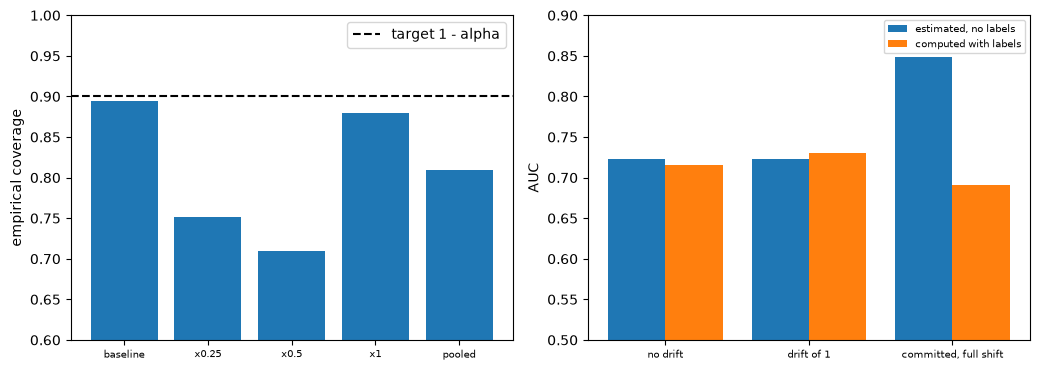

In [9]:
# Left: committed coverage per window with the target; right: estimated against labelled AUC
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8))
names = [seg.replace("window:", "").replace("fed-higher-risk-", "") for seg in rebuilt]
left.bar(names, [cover.coverage for _, cover in rebuilt.values()], color="tab:blue")
left.axhline(0.9, color="black", linestyle="--", label="target 1 - alpha")
left.set_ylim(0.6, 1.0)
left.set_ylabel("empirical coverage")
left.tick_params(axis="x", labelsize=7)
left.legend()
groups, estimated, labelled = [], [], []
for label, (plant, d, sets, cover) in windows.items():
    groups.append(label)
    estimated.append(cbpe.cbpe_auc(d["p_test"]).estimated_auc)
    labelled.append(float(disc.disc_auc(d["p_test"], d["y_test"]).metric))
groups.append("committed, full shift")
estimated.append(label_free["estimated_auc"])
labelled.append(full_shift["metric"]["auc"])
position = np.arange(len(groups))
right.bar(position - 0.2, estimated, width=0.4, label="estimated, no labels")
right.bar(position + 0.2, labelled, width=0.4, label="computed with labels")
right.set_xticks(position)
right.set_xticklabels(groups, fontsize=7)
right.set_ylim(0.5, 0.9)
right.set_ylabel("AUC")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **The rank is an integer problem.** For 149 scores at $\alpha = 0.18$ the float product is 123.00000000000001, a naive ceiling gives 124, and the engine uses the score of rank 123. With fewer calibration points than the rank requires, the quantile is infinite and the set is every label.
- **The sets cover what they promise under exchangeability, and not after a drift.** On the plant the sets cover 0.8985 of the test window without drift (the exact value is 0.9000, the target 0.90; Beta-Binomial p = 0.8311, green) and 0.7995 with a drift of one unit of log-odds (exact 0.8010; p = 1.494e-36, red). The quantile is the same in both (0.7075): the calibration window did not change, the test window did.
- **The law of the count matters when the test window is not small against the calibration window.** On the plant ($n_{\mathrm{cal}} = 20{,}000$, $m = 2{,}000$) the two p-values are close (0.8311 and 0.823). On the committed baseline window ($n_{\mathrm{cal}} = 1{,}471$, $m = 3{,}151$) they are 0.523 (Beta-Binomial) and 0.313 (binomial): the binomial form ignores the randomness of the calibration quantile. Rebuilt from the committed covered count, the engine reproduces every committed p-value and light: baseline 0.8946 (green), the three shifted windows 0.7509 and 0.7099 (red) and 0.8800 (amber, p = 0.0372), and the four pooled windows 0.8089 over 12,604 rows (red). The binomial p-values (3.69e-127 for the first shift) say the same in a stronger tone, which is what makes them a poor guide to size. The coverage is not monotone in the shift: the pipeline sized the shifts by the PSI of the score, and the document does not explain why the largest one loses less coverage than the middle ones.
- **CBPE reads probabilities and nothing else.** The expected confusion counts add up to the 2,000 rows; the estimated AUC is 0.7223 for both plant windows, because the probabilities are the same, whatever the labels do. The AUC computed with labels is 0.7155 without drift and 0.7306 with it: a drift in the log-odds is almost monotone and moves the ranking little, so the estimate is close in both windows, and what the drift changes is the calibration, which the coverage test sees (0.8985 against 0.7995) and the AUC does not. On the committed full shift the estimate is 0.8481 and the AUC computed with labels is 0.6914: the estimate is 0.1567 too high, because the shifted rows leave the region the model was fitted on (the third assumption).
- **The engine never lets the estimate take a light.** The row is `not_evaluated`, its statistic is not a number, and the estimated AUC and its four assumptions are in the result. The committed row has the same shape.

What the results do not show: the plant is synthetic and its drift is chosen; the committed shifts are synthetic displacements of a real holdout sized by the PSI of a rating, so the coverage losses say what the test does, not how a real portfolio shifts; the conformal guarantee needs exchangeability, and a coverage loss is read as a symptom of its failure, never as proof; and the cut points (0.05, 0.01) are conventions.

## Summary

- The split-conformal quantile is the $k$-th smallest calibration score with $k = \lceil (n+1)(1-\alpha) \rceil$ computed on the exact decimal of $\alpha$; the sets cover at least $1 - \alpha$ under exchangeability.
- The covered count of the test window is Beta-Binomial given the calibration size; the engine's light reads that p-value, and the dossier's binomial p-value sits beside it.
- Out of time, a coverage below the target is a symptom of broken exchangeability; the committed Federal Reserve windows lose coverage in three of four windows, the engine reproducing every committed p-value and light.
- CBPE estimates the AUC from calibrated probabilities alone under four assumptions, always labelled an estimate; its engine row never takes a light. It is 0.1567 too high on the committed full shift, where the shifted rows leave the fitted region.
- Coverage sees a change of calibration that the AUC does not; the two answer different questions.

**What to try next.** Notebook 05 compares a champion with a challenger by a paired Brier bootstrap. Notebook 09 measures the size of the conformal coverage test with the binomial and with the Beta-Binomial null.

## References

- Angelopoulos, A. N. and Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- Vovk, V., Gammerman, A. and Shafer, G. (2022), Algorithmic Learning in a Random World, 2nd edition, Springer, https://doi.org/10.1007/978-3-031-06649-8
- NannyML, how confidence-based performance estimation (CBPE) works. https://nannyml.readthedocs.io/en/stable/how_it_works/performance_estimation.html
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- EBA (2023), Follow-up report on machine learning for IRB models, EBA/REP/2023/28. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2023/1061483/Follow-up%20report%20on%20machine%20learning%20for%20IRB%20models.pdf
- MAPIE (BSD-3-Clause), conformal prediction for scikit-learn. https://github.com/scikit-learn-contrib/MAPIE